<a href="https://colab.research.google.com/github/Robin-FIME/InteligenciaArtificial_y_RedesNeuronales_UANL_FIME/blob/main/ACTIVIDADES/AF7_RNP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Actividad 7: Redes Neuronales Artificiales**
-**Grupo:** 004 -**Horario de clase:** Jueves N1 a N3
* **2066292**	Gabriel Alejandro Almanza Mata	**IMC**

* **2100051**	Alfredo René Robles Guzman	**IMC**

* **2177682**	Luis Mauricio Torres Mayorga **IMC**

* **2111623** Valeria Monserrat Rincón Vásquez **IMC**

* **1930458** Juan Carlos Torres Gonzales **IMC**


In [55]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
import numpy as np
import matplotlib.pyplot as plt

In [56]:
(train_data, train_labels), (test_data, test_label) = mnist.load_data()

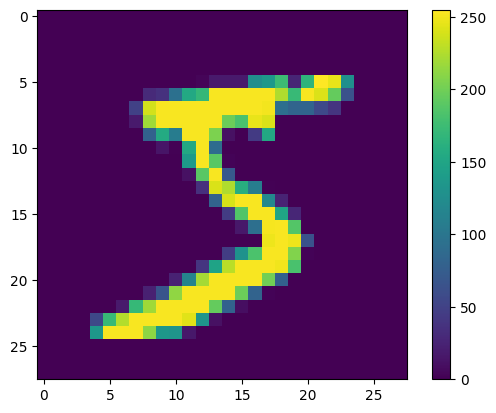

In [57]:
plt.figure()
plt.imshow(train_data[0])
plt.colorbar()
plt.grid(False)
plt.show()

In [58]:
train_data = train_data / 255.0
test_data = test_data / 255.0

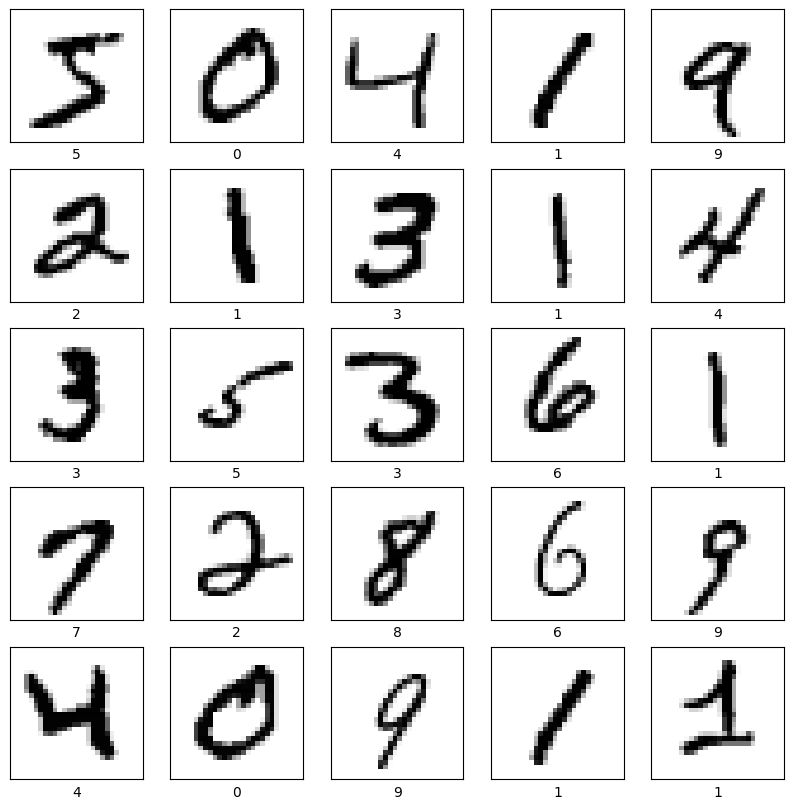

In [59]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_data[i], cmap=plt.cm.binary)
    plt.xlabel(train_labels[i])
plt.show()

In [60]:
# Propuesta de estructura de red neuronal =)
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax') # Capa de salida con softmax
])

# Compilación: Optimizador, función de pérdida y métrica
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Entrenamiento con la función "fit"
model.fit(train_data, train_labels, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9280 - loss: 0.2542
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9681 - loss: 0.1098
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9771 - loss: 0.0771
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9829 - loss: 0.0564
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9859 - loss: 0.0443


In [61]:
test_loss, test_acc = model.evaluate(test_data, test_label, verbose=2)
print('\nExactitud (accuracy) con test_data:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.9760 - loss: 0.0747

Exactitud (accuracy) con test_data: 0.9760000109672546


In [66]:
# Generar todas las predicciones del conjunto de prueba
predicciones = model.predict(test_data)

# Función para graficar la imagen y la etiqueta
def plot_image(i, predictions_array, true_label, img):
    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img, cmap=plt.cm.binary)

    predicted_label = np.argmax(predictions_array)

    # Forzamos a que el texto de la probabilidad siempre sea rojo
    color = 'red'

    plt.xlabel("{} {:2.0f}% ({})".format(predicted_label,
                                  100*np.max(predictions_array),
                                  true_label),
                                  color=color)

# Función para graficar el arreglo de probabilidades
def plot_value_array(i, predictions_array, true_label):
    true_label = true_label[i]
    plt.grid(False)
    plt.xticks(range(10))
    plt.yticks([])

    # Barras base en gris clásico para que resalte el rojo
    thisplot = plt.bar(range(10), predictions_array, color="#777777")
    plt.ylim([0, 1])

    predicted_label = np.argmax(predictions_array)

    # Coloreamos de rojo tanto la barra predicha como la del valor real
    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('red')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


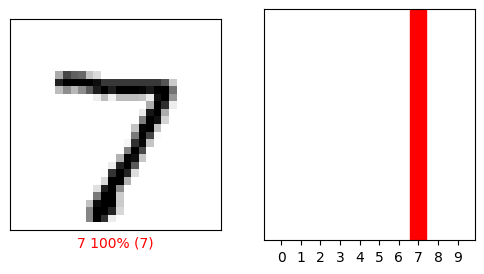

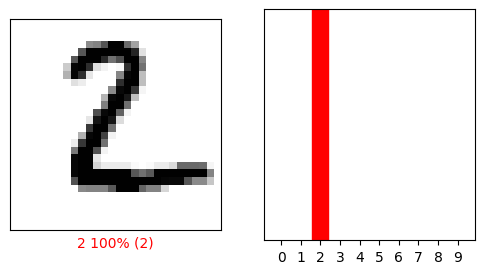

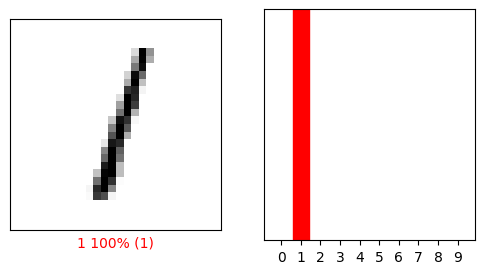

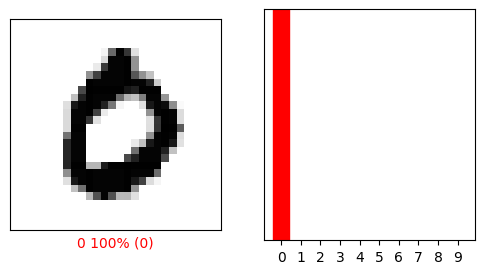

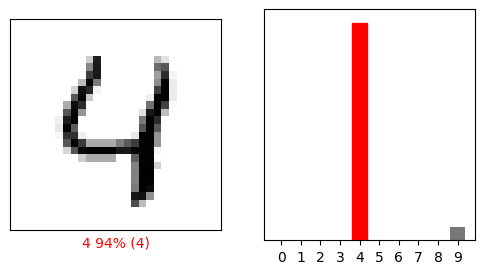

In [67]:
# Mostrar 5 predicciones diferentes
num_predicciones = 5

for i in range(num_predicciones):
    plt.figure(figsize=(6,3))

    # Subplot de la imagen (izquierda)
    plt.subplot(1,2,1)
    plot_image(i, predicciones[i], test_label, test_data)

    # Subplot de la gráfica de barras (derecha)
    plt.subplot(1,2,2)
    plot_value_array(i, predicciones[i], test_label)

    plt.show()